# **Latin Morphological Analyser** - Ablation Study

This notebook trains and evaluates a baseline variant of the morphological analyser **without POS conditioning** in the feature heads, then compares it against the main POS-conditioned model trained in notebook 2. The goal is to test whether the soft POS conditioning earns its complexity.

Single variable changed: the feature heads in the baseline receive only the BERT representation. Everything else (BERT backbone, POS head, POS-feature mask used for loss masking, hyperparameters, data splits) is identical to notebook 2.

## **Set Up Environment**

In [1]:
import os

### Install Latin BERT

Download the pre-trained Latin BERT model from the GitHub repository and define the path for the model to be used for fine-tuning.

In [2]:
# clone latin bert repo
!git clone https://github.com/dbamman/latin-bert.git
%cd latin-bert

Cloning into 'latin-bert'...
remote: Enumerating objects: 154, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (29/29), done.
remote: Total 154 (delta 4), reused 27 (delta 3), pack-reused 122 (from 1)
Receiving objects: 100% (154/154), 6.77 MiB | 14.87 MiB/s, done.
Resolving deltas: 100% (59/59), done.
/content/latin-bert


In [3]:
# Download pre-trained BERT model for Latin
!./scripts/download.sh

--2026-05-22 06:48:00--  https://drive.usercontent.google.com/download?export=download&id=1Te_14UB-DZ8wYPhHGyDg7LadDTjNzpti&confirm=t&uuid=edf8e2f4-ce5a-4b41-903a-dc2cfd47cf4f
Resolving drive.usercontent.google.com (drive.usercontent.google.com)... 172.217.218.132, 2a00:1450:4013:c08::84
Connecting to drive.usercontent.google.com (drive.usercontent.google.com)|172.217.218.132|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 448020480 (427M) [application/octet-stream]
Saving to: ‘latin_bert.tar’

latin_bert.tar      100%[===================>] 427.27M  64.0MB/s    in 6.4s    

2026-05-22 06:48:07 (66.7 MB/s) - ‘latin_bert.tar’ saved [448020480/448020480]



In [4]:
!ls -lah models/latin_bert | head

total 428M
drwxrwxr-x 2 1001 1001 4.0K Sep  4  2020 .
drwxr-xr-x 4 root root 4.0K May 22 06:48 ..
-rw-rw-r-- 1 1001 1001  503 Sep  4  2020 config.json
-rw-rw-r-- 1 1001 1001 428M Sep  4  2020 pytorch_model.bin
-rw-rw-r-- 1 1001 1001 217K Sep  4  2020 vocab.txt


In [5]:
%cd ..

/content


In [6]:
MODEL_PATH = os.path.join("latin-bert", "models", "latin_bert")

### Import Dependencies

1. Import all required libraries.
2. Mount Google Drive for storage access.
3. Setup HuggingFace access through token.
4. Define available device to be used.
5. Import shared definitions.

In [7]:
import sys
import json
import time
import torch
import numpy as np
import pandas as pd
from safetensors.torch import load_file
import transformers
from transformers import AutoTokenizer, TrainingArguments, Trainer
import datasets
from datasets import load_from_disk
import sklearn
from sklearn.metrics import classification_report, accuracy_score, f1_score
from statsmodels.stats.contingency_tables import mcnemar
import matplotlib
import matplotlib.pyplot as plt

In [8]:
%matplotlib inline

In [9]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [10]:
from huggingface_hub import login
from google.colab import userdata

login(token=userdata.get('HF_TOKEN'))

In [11]:
print(torch.cuda.is_available())
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using device:", device)

True
Using device: cuda


In [12]:
# Import shared definitions (constants, dataclasses, model classes, data collator)
sys.path.append('/content/drive/MyDrive/FYP')
from morph_constants import FEATURE_ORDER, POS_FEATURE_MASK, ALL_FEATS, IGNORE_INDEX
from morphological_analyser import LatinMorphologicalAnalyserConfig, LatinMorphologicalAnalyser, MultiLabelDataCollator
from morphological_analyser_ablation import LatinMorphologicalAnalyserNoPOSCondConfig, LatinMorphologicalAnalyserNoPOSCond

In [13]:
print("Python:", sys.version.split()[0])
print("PyTorch:", torch.__version__)
print("Transformers:", transformers.__version__)
print("Datasets:", datasets.__version__)
print("scikit-learn:", sklearn.__version__)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)
print("Matplotlib:", matplotlib.__version__)
print("CUDA:", torch.version.cuda)
print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "none")

Python: 3.12.13
PyTorch: 2.10.0+cu128
Transformers: 5.0.0
Datasets: 4.0.0
scikit-learn: 1.6.1
NumPy: 2.0.2
pandas: 2.2.2
Matplotlib: 3.10.0
CUDA: 12.8
GPU: Tesla T4


## **Load Processed Data**

Reuse the exact same train/val/test split and label vocabularies from notebook 1 so the two models are trained and evaluated on identical data.

In [14]:
# Load tokenized datasets and label vocabularies
PROCESSED_DIR = "/content/drive/MyDrive/FYP/processed"

train_ds = load_from_disk(f"{PROCESSED_DIR}/train_ds")
val_ds   = load_from_disk(f"{PROCESSED_DIR}/val_ds")
test_ds  = load_from_disk(f"{PROCESSED_DIR}/test_ds")

with open(f"{PROCESSED_DIR}/label2id_all.json") as f:
    label2id_all = json.load(f)

with open(f"{PROCESSED_DIR}/id2label_all.json") as f:
    id2label_all_str = json.load(f)

# id2label_all needs int keys
id2label_all = {feat: {int(k): v for k, v in d.items()} for feat, d in id2label_all_str.items()}

print(f"{len(train_ds)} train | {len(val_ds)} val | {len(test_ds)} test")

8295 train | 1778 val | 1778 test


In [15]:
# Re-load the tokenizer
tokenizer = AutoTokenizer.from_pretrained(MODEL_PATH)

## **POS-feature compatibility mask tensor**


Same helper as notebooks 2 and 3, needed for both training and evaluation.

In [16]:
def build_pos_mask_tensor(label2id_pos, device):
    """
    Build a (num_pos, num_features) bool tensor directly from POS_FEATURE_MASK.
    Any POS code not listed in POS_FEATURE_MASK gets all-False (no features).
    Unknown codes are reported so you can add them explicitly.
    """
    num_pos   = len(label2id_pos)
    num_feats = len(FEATURE_ORDER)
    mask      = torch.zeros(num_pos, num_feats, dtype=torch.bool)

    for pos_code, pos_idx in label2id_pos.items():
        if pos_code in POS_FEATURE_MASK:
            for fi, applicable in enumerate(POS_FEATURE_MASK[pos_code]):
                mask[pos_idx, fi] = applicable
        else:
            # Surface any unmapped codes immediately rather than silently
            # treating them as all-False
            print(f"WARNING: POS code '{pos_code}' not in POS_FEATURE_MASK "
                  f"— all features will be masked off for this tag. "
                  f"Add it explicitly.")

    return mask.to(device)

In [17]:
pos_mask_tensor = build_pos_mask_tensor(label2id_all["pos"], device)

In [18]:
# Sanity checks - print the mask for every code in your corpus
print(f"{'Code':<6} {'Features active':}")
for pos_code, pos_idx in sorted(label2id_all["pos"].items()):
    active = [f for fi, f in enumerate(FEATURE_ORDER)
              if pos_mask_tensor[pos_idx, fi].item()]
    print(f"  {pos_code:<6} {active if active else '—'}")

Code   Features active
  A-     ['number', 'gender', 'case', 'degree']
  C-     —
  Df     ['degree']
  Dq     —
  Du     —
  F-     —
  G-     —
  I-     —
  Ma     ['number', 'gender', 'case']
  Mo     ['number', 'gender', 'case']
  Nb     ['number', 'gender', 'case']
  Ne     ['number', 'gender', 'case']
  Pc     ['number', 'gender', 'case']
  Pd     ['number', 'gender', 'case']
  Pi     ['number', 'gender', 'case']
  Pk     ['person', 'number', 'gender', 'case']
  Pp     ['person', 'number', 'gender', 'case']
  Pr     ['number', 'gender', 'case']
  Ps     ['person', 'number', 'gender', 'case']
  Pt     ['person', 'number', 'gender', 'case']
  Px     ['number', 'gender', 'case']
  R-     —
  V-     ['person', 'number', 'tense', 'mood', 'voice']


## **Part A: Train the Baseline Model (No POS Conditioning)**


Same two-phase schedule as notebook 2: frozen BERT + heads only, then full fine-tune.

In [19]:
# Define a path for a dummy file to satisfy transformers' internal checks in colab
dummy_file_path = 'latin_morphological_analyser_ablation_model.py'

# Create the dummy file if it doesn't exist
if not os.path.exists(dummy_file_path):
    with open(dummy_file_path, 'w') as f:
        f.write("# Dummy file for __main__ module in Colab to satisfy transformers library checks\n")

sys.modules['__main__'].__file__ = dummy_file_path

### Load Baseline Model

In [20]:
num_labels_per_feat = {feat: len(vocab) for feat, vocab in label2id_all.items()}

ablation_config = LatinMorphologicalAnalyserNoPOSCondConfig(
    bert_model_path     = MODEL_PATH,
    num_labels_per_feat = num_labels_per_feat,
    label2id_all        = label2id_all,
    id2label_all        = {feat: {str(k): v for k, v in d.items()} for feat, d in id2label_all.items()},
    pos_feature_mask    = POS_FEATURE_MASK,
    dropout             = 0.1,
)

model_ablation = LatinMorphologicalAnalyserNoPOSCond(ablation_config).to(device)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: latin-bert/models/latin_bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


### Parameter Count Comparison

Quick check on how many parameters each architecture has (one of the things you're trading off).

In [21]:
ablation_params = sum(p.numel() for p in model_ablation.parameters() if p.requires_grad)
print(f"Baseline (no POS conditioning) trainable parameters: {ablation_params:,}")

# Build a fresh conditioned model just to count its params
_cond_config_for_counting = LatinMorphologicalAnalyserConfig(
    bert_model_path     = MODEL_PATH,
    num_labels_per_feat = num_labels_per_feat,
    label2id_all        = label2id_all,
    id2label_all        = {feat: {str(k): v for k, v in d.items()} for feat, d in id2label_all.items()},
    pos_feature_mask    = POS_FEATURE_MASK,
    pos_embed_dim       = 64,
    dropout             = 0.1,
)
_cond_for_counting = LatinMorphologicalAnalyser(_cond_config_for_counting)
cond_params = sum(p.numel() for p in _cond_for_counting.parameters() if p.requires_grad)
print(f"Conditioned (with POS conditioning) trainable parameters: {cond_params:,}")

print(f"Difference: {cond_params - ablation_params:+,} ({100 * (cond_params - ablation_params) / ablation_params:+.2f}%)")

del _cond_for_counting, _cond_config_for_counting

Baseline (no POS conditioning) trainable parameters: 112,912,708


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: latin-bert/models/latin_bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Conditioned (with POS conditioning) trainable parameters: 113,045,252
Difference: +132,544 (+0.12%)


In [22]:
print(model_ablation)

LatinMorphologicalAnalyserNoPOSCond(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32900, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=

### Define Custom Data Collator

In [23]:
data_collator_multi = MultiLabelDataCollator(
    tokenizer  = tokenizer,
    feat_names = ALL_FEATS,
)

### Compute Metrics Function

POS accuracy shown during training

In [24]:
def compute_metrics_pos(eval_pred):
    """
    Trainer passes EvalPrediction(predictions, label_ids).
    predictions will be pos_logits and label_ids will be labels_pos.
    Compute POS-level metrics for monitoring.
    """
    # If eval_pred.predictions is a tuple, take the first element (pos_logits)
    if isinstance(eval_pred.predictions, tuple):
        logits = eval_pred.predictions[0]
    else:
        logits = eval_pred.predictions

    # If eval_pred.label_ids is a tuple, take the first element (labels_pos)
    # as compute_metrics_pos is specifically for POS.
    if isinstance(eval_pred.label_ids, tuple):
        labels_pos = eval_pred.label_ids[0]
    else:
        labels_pos = eval_pred.label_ids

    preds_pos = np.argmax(logits, axis=-1)

    true_flat, pred_flat = [], []
    for pred_row, label_row in zip(preds_pos, labels_pos):
            for p, l in zip(pred_row, label_row):
                if l != IGNORE_INDEX:
                    true_flat.append(l)
                    pred_flat.append(p)

    report = classification_report(
        true_flat, pred_flat,
        labels      = list(range(len(id2label_all["pos"]))),
        target_names= [id2label_all["pos"][i]
                       for i in range(len(id2label_all["pos"]))],
        output_dict = True,
        zero_division = 0,
    )
    return {
        "pos_accuracy":    report["accuracy"],
        "pos_f1_macro":    report["macro avg"]["f1-score"],
        "pos_f1_weighted": report["weighted avg"]["f1-score"],
    }

### Phase 1

In [25]:
for param in model_ablation.bert.parameters():
    param.requires_grad = False

In [26]:
args_phase1 = TrainingArguments(
    output_dir                 = "amysp/latin-morphological-analyser-ablation",
    push_to_hub                = True,
    hub_strategy               = "every_save",
    hub_private_repo           = True,
    eval_strategy              = "epoch",
    save_strategy              = "epoch",
    learning_rate              = 1e-3,
    per_device_train_batch_size= 32,
    per_device_eval_batch_size = 32,
    num_train_epochs           = 2,
    weight_decay               = 0.01,
    load_best_model_at_end     = True,
    save_total_limit           = 1,
    metric_for_best_model      = "pos_accuracy",
    greater_is_better          = True,
    report_to                  = "none",
    fp16                       = True,
)

In [27]:
trainer_p1 = Trainer(
    model           = model_ablation,
    args            = args_phase1,
    train_dataset   = train_ds,
    eval_dataset    = val_ds,
    data_collator   = data_collator_multi,
    compute_metrics = compute_metrics_pos,
)

In [28]:
trainer_p1.train()

Epoch,Training Loss,Validation Loss,Pos Accuracy,Pos F1 Macro,Pos F1 Weighted
1,No log,6.760167,0.668742,0.458106,0.640435
2,7.379212,6.522889,0.677960,0.487085,0.652865


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=520, training_loss=7.349496166522687, metrics={'train_runtime': 86.7818, 'train_samples_per_second': 191.169, 'train_steps_per_second': 5.992, 'total_flos': 1111672352286720.0, 'train_loss': 7.349496166522687, 'epoch': 2.0})

### Phase 2

In [29]:
for param in model_ablation.bert.parameters():
    param.requires_grad = True

In [30]:
args_phase2 = TrainingArguments(
    output_dir                 = "amysp/latin-morphological-analyser-ablation",
    push_to_hub                = True,
    hub_strategy               = "every_save",
    hub_private_repo           = True,
    eval_strategy              = "epoch",
    save_strategy              = "epoch",
    learning_rate              = 2e-5,
    per_device_train_batch_size= 32,
    per_device_eval_batch_size = 32,
    num_train_epochs           = 50,
    weight_decay               = 0.01,
    load_best_model_at_end     = True,
    save_total_limit           = 1,
    metric_for_best_model      = "pos_accuracy",
    greater_is_better          = True,
    report_to                  = "none",
    fp16                       = True,
)

In [31]:
trainer_p2 = Trainer(
    model           = model_ablation,
    args            = args_phase2,
    train_dataset   = train_ds,
    eval_dataset    = val_ds,
    data_collator   = data_collator_multi,
    compute_metrics = compute_metrics_pos,
    callbacks       = [transformers.EarlyStoppingCallback(early_stopping_patience=2)],
)

In [32]:
trainer_p2.train()

Epoch,Training Loss,Validation Loss,Pos Accuracy,Pos F1 Macro,Pos F1 Weighted
1,No log,5.470534,0.736681,0.566630,0.721869
2,5.502923,5.284178,0.746498,0.582625,0.733253
3,5.502923,5.240121,0.749312,0.592834,0.739604
4,4.833687,5.232417,0.751287,0.596159,0.741997
5,4.833687,5.248704,0.752843,0.601710,0.745178
6,4.333171,5.308080,0.754938,0.609370,0.745942
7,4.333171,5.394288,0.755597,0.612207,0.746846
8,3.939337,5.444672,0.754998,0.613234,0.747911
9,3.939337,5.656948,0.754699,0.609242,0.746345


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=2340, training_loss=4.503281552567441, metrics={'train_runtime': 725.6917, 'train_samples_per_second': 571.524, 'train_steps_per_second': 17.914, 'total_flos': 5002525585290240.0, 'train_loss': 4.503281552567441, 'epoch': 9.0})

### Plot Training vs Validation Loss Curve

In [33]:
trainer_p2.state.log_history

[{'eval_loss': 5.470533847808838,
  'eval_pos_accuracy': 0.7366814318209026,
  'eval_pos_f1_macro': 0.5666301067608874,
  'eval_pos_f1_weighted': 0.7218692158439591,
  'eval_runtime': 5.4454,
  'eval_samples_per_second': 326.516,
  'eval_steps_per_second': 10.284,
  'epoch': 1.0,
  'step': 260},
 {'loss': 5.5029228515625,
  'grad_norm': 12.9937105178833,
  'learning_rate': 1.9232307692307693e-05,
  'epoch': 1.9230769230769231,
  'step': 500},
 {'eval_loss': 5.284178256988525,
  'eval_pos_accuracy': 0.7464982640967317,
  'eval_pos_f1_macro': 0.58262475557634,
  'eval_pos_f1_weighted': 0.7332531527381342,
  'eval_runtime': 4.4154,
  'eval_samples_per_second': 402.682,
  'eval_steps_per_second': 12.683,
  'epoch': 2.0,
  'step': 520},
 {'eval_loss': 5.240121364593506,
  'eval_pos_accuracy': 0.7493116245660242,
  'eval_pos_f1_macro': 0.5928343688950439,
  'eval_pos_f1_weighted': 0.7396041173871823,
  'eval_runtime': 5.2939,
  'eval_samples_per_second': 335.859,
  'eval_steps_per_second': 1

In [34]:
# get training log history
log_history = trainer_p2.state.log_history

train_epochs = []
train_loss = []

val_epochs = []
val_loss = []

for entry in log_history:
    # training loss
    if "loss" in entry and "epoch" in entry:
        train_epochs.append(entry["epoch"])
        train_loss.append(entry["loss"])

    # validation loss
    if "eval_loss" in entry:
        val_epochs.append(entry["epoch"])
        val_loss.append(entry["eval_loss"])

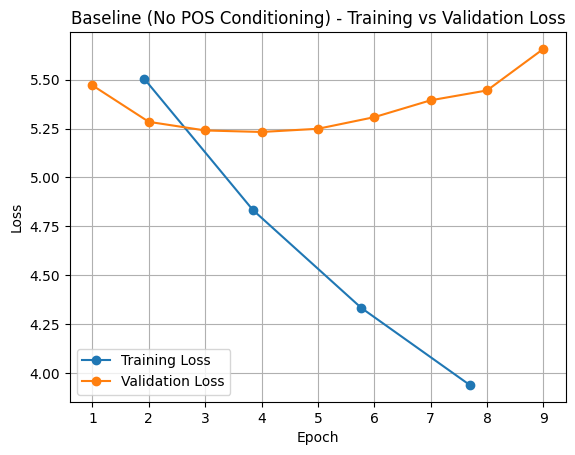

In [35]:
# plot training vs val loss
plt.figure()

plt.plot(train_epochs, train_loss, marker='o', label="Training Loss")
plt.plot(val_epochs, val_loss, marker='o', label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Baseline (No POS Conditioning) - Training vs Validation Loss")
plt.legend()
plt.grid(True)

plt.show()

### Evaluate Finetuned Model

In [36]:
# evaluate finetuned model
results = trainer_p2.evaluate()
results

{'eval_loss': 5.394287586212158,
 'eval_pos_accuracy': 0.7555967915718903,
 'eval_pos_f1_macro': 0.61220700686664,
 'eval_pos_f1_weighted': 0.74684647530877,
 'eval_runtime': 4.4528,
 'eval_samples_per_second': 399.297,
 'eval_steps_per_second': 12.576,
 'epoch': 9.0}

### Save Baseline Model

In [37]:
ABLATION_DIR = "/content/drive/MyDrive/FYP/morphological_analyser_ablation"
model_ablation.save_pretrained(ABLATION_DIR)
tokenizer.save_pretrained(ABLATION_DIR)
model_ablation.push_to_hub("amysp/latin-morphological-analyser-ablation")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

README.md: 0.00B [00:00, ?B/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...6f959am/model.safetensors:  19%|#9        | 87.9MB /  452MB            

CommitInfo(commit_url='https://huggingface.co/amysp/latin-morphological-analyser-ablation/commit/fe02b0c8fc4bb99fa81910846294f8c4be7073f4', commit_message='Upload LatinMorphologicalAnalyserNoPOSCond', commit_description='', oid='fe02b0c8fc4bb99fa81910846294f8c4be7073f4', pr_url=None, repo_url=RepoUrl('https://huggingface.co/amysp/latin-morphological-analyser-ablation', endpoint='https://huggingface.co', repo_type='model', repo_id='amysp/latin-morphological-analyser-ablation'), pr_revision=None, pr_num=None)

## **Part B: Compare the Two Models**

Load both trained models, run them on the test set, and produce a side-by-side comparison of per-feature performance.

### **Load POS-Conditioned Model**

In [38]:
COND_DIR = "/content/drive/MyDrive/FYP/morphological_analyser_multihead"

with open(os.path.join(COND_DIR, "config.json")) as f:
    cond_config_dict = json.load(f)

cond_config = LatinMorphologicalAnalyserConfig(
    bert_model_path     = MODEL_PATH,
    num_labels_per_feat = cond_config_dict["num_labels_per_feat"],
    label2id_all        = cond_config_dict["label2id_all"],
    id2label_all        = {feat: {str(k): v for k, v in d.items()} for feat, d in cond_config_dict["id2label_all"].items()},
    pos_feature_mask    = cond_config_dict["pos_feature_mask"],
    pos_embed_dim       = 64,
    dropout             = 0.1,
)

model_cond = LatinMorphologicalAnalyser(cond_config).to(device)
state_dict = load_file(
    os.path.join(COND_DIR, "model.safetensors"),
    device=device,
)
_missing, _unexpected = model_cond.load_state_dict(state_dict, strict=False)
model_cond.eval()

print("Loaded POS-conditioned model from", COND_DIR)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: latin-bert/models/latin_bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loaded POS-conditioned model from /content/drive/MyDrive/FYP/morphological_analyser_multihead


In [39]:
print(model_cond)

LatinMorphologicalAnalyser(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32900, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=1e-12, el

### **Re-load Baseline Model**

In [40]:
model_ablation_loaded = LatinMorphologicalAnalyserNoPOSCond(ablation_config).to(device)
state_dict_abl = load_file(
    os.path.join(ABLATION_DIR, "model.safetensors"),
    device=device,
)
model_ablation_loaded.load_state_dict(state_dict_abl, strict=False)
model_ablation_loaded.eval()

print("Re-loaded baseline model from", ABLATION_DIR)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

BertModel LOAD REPORT from: latin-bert/models/latin_bert
Key                                        | Status     |  | 
-------------------------------------------+------------+--+-
cls.seq_relationship.bias                  | UNEXPECTED |  | 
cls.predictions.decoder.weight             | UNEXPECTED |  | 
cls.predictions.transform.dense.weight     | UNEXPECTED |  | 
cls.seq_relationship.weight                | UNEXPECTED |  | 
cls.predictions.transform.dense.bias       | UNEXPECTED |  | 
cls.predictions.bias                       | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.bias   | UNEXPECTED |  | 
cls.predictions.decoder.bias               | UNEXPECTED |  | 
cls.predictions.transform.LayerNorm.weight | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Re-loaded baseline model from /content/drive/MyDrive/FYP/morphological_analyser_ablation


In [41]:
print(model_ablation_loaded)

LatinMorphologicalAnalyserNoPOSCond(
  (bert): BertModel(
    (embeddings): BertEmbeddings(
      (word_embeddings): Embedding(32900, 768, padding_idx=0)
      (position_embeddings): Embedding(512, 768)
      (token_type_embeddings): Embedding(2, 768)
      (LayerNorm): LayerNorm((768,), eps=1e-12, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
    )
    (encoder): BertEncoder(
      (layer): ModuleList(
        (0-11): 12 x BertLayer(
          (attention): BertAttention(
            (self): BertSelfAttention(
              (query): Linear(in_features=768, out_features=768, bias=True)
              (key): Linear(in_features=768, out_features=768, bias=True)
              (value): Linear(in_features=768, out_features=768, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): BertSelfOutput(
              (dense): Linear(in_features=768, out_features=768, bias=True)
              (LayerNorm): LayerNorm((768,), eps=

### **Evaluation Helper**

This is a variant of `evaluate_all_features` from notebook 3 that returns the predictions and reports as dicts instead of just printing them, so they can be compared programmatically.

In [42]:
from torch.utils.data import DataLoader

def collect_predictions(model, dataset, tokenizer, device,
                        pos_mask_tensor, data_collator, batch_size=32):
    """
    Run inference over the dataset and collect per-feature
    (y_true, y_pred) lists. Only includes tokens where the
    feature is applicable for the token's TRUE POS.

    Returns: dict[feat] -> {'y_true': list[int], 'y_pred': list[int]}
    """
    model.eval()

    feat_true = {feat: [] for feat in ALL_FEATS}
    feat_pred = {feat: [] for feat in ALL_FEATS}

    loader = DataLoader(
        dataset.with_format("torch"),
        batch_size=batch_size,
        collate_fn=data_collator,
    )

    for batch in loader:
        batch = {k: v.to(device) for k, v in batch.items()}
        with torch.no_grad():
            output = model(
                input_ids      = batch["input_ids"],
                attention_mask = batch["attention_mask"],
            )

        pos_logits     = output.logits
        feature_logits = output.feature_logits
        pred_pos       = pos_logits.argmax(dim=-1)
        true_pos       = batch["labels_pos"]

        valid = true_pos != IGNORE_INDEX

        feat_true["pos"].extend(true_pos[valid].cpu().tolist())
        feat_pred["pos"].extend(pred_pos[valid].cpu().tolist())

        for feat_idx, feat in enumerate(FEATURE_ORDER):
            true_feat = batch[f"labels_{feat}"]

            pos_clamp   = true_pos.clone()
            pos_clamp[~valid] = 0
            applicable  = pos_mask_tensor[pos_clamp, feat_idx] & valid

            if applicable.any():
                pred_feat = feature_logits[feat].argmax(dim=-1)
                feat_true[feat].extend(true_feat[applicable].cpu().tolist())
                feat_pred[feat].extend(pred_feat[applicable].cpu().tolist())

    return {feat: {'y_true': feat_true[feat], 'y_pred': feat_pred[feat]}
            for feat in ALL_FEATS}

In [43]:
def per_feature_reports(predictions, id2label_all):
    """Build a classification report dict for each feature."""
    reports = {}
    for feat, d in predictions.items():
        if not d['y_true']:
            continue
        num_labels = len(id2label_all[feat])
        reports[feat] = classification_report(
            d['y_true'], d['y_pred'],
            labels       = list(range(num_labels)),
            target_names = [id2label_all[feat][i] for i in range(num_labels)],
            output_dict  = True,
            zero_division= 0,
        )
    return reports

### **Run Both Models on the Test Set**

In [44]:
preds_cond = collect_predictions(
    model_cond, test_ds, tokenizer, device,
    pos_mask_tensor, data_collator_multi,
)
reports_cond = per_feature_reports(preds_cond, id2label_all)
print("POS-conditioned model: done")

POS-conditioned model: done


In [45]:
preds_ablation = collect_predictions(
    model_ablation_loaded, test_ds, tokenizer, device,
    pos_mask_tensor, data_collator_multi,
)
reports_ablation = per_feature_reports(preds_ablation, id2label_all)
print("Baseline (no POS conditioning) model: done")

Baseline (no POS conditioning) model: done


### **Side-by-Side Comparison Table**

Per-feature accuracy, macro-F1, and weighted-F1 for both models, plus the absolute difference (conditioned - baseline).

In [46]:
rows = []
for feat in ALL_FEATS:
    if feat not in reports_cond or feat not in reports_ablation:
        continue
    rc, ra = reports_cond[feat], reports_ablation[feat]
    n_support = sum(rc[k]['support'] for k in rc
                    if k not in ('accuracy', 'macro avg', 'weighted avg'))
    rows.append({
        'feature':       feat,
        'n_test_tokens': int(n_support),
        'acc_cond':      rc['accuracy'],
        'acc_ablation':  ra['accuracy'],
        'acc_diff':      rc['accuracy'] - ra['accuracy'],
        'f1macro_cond':     rc['macro avg']['f1-score'],
        'f1macro_ablation': ra['macro avg']['f1-score'],
        'f1macro_diff':     rc['macro avg']['f1-score'] - ra['macro avg']['f1-score'],
        'f1weighted_cond':     rc['weighted avg']['f1-score'],
        'f1weighted_ablation': ra['weighted avg']['f1-score'],
        'f1weighted_diff':     rc['weighted avg']['f1-score'] - ra['weighted avg']['f1-score'],
    })

summary_df = pd.DataFrame(rows)
summary_df.round(4)

,feature,n_test_tokens,acc_cond,acc_ablation,acc_diff,f1macro_cond,f1macro_ablation,f1macro_diff,f1weighted_cond,f1weighted_ablation,f1weighted_diff
0,pos,16423,0.7612,0.7611,0.0001,0.6190,0.6199,-0.0009,0.7530,0.7529,0.0001
1,person,5541,0.7944,0.7921,0.0023,0.7519,0.7486,0.0033,0.7907,0.7882,0.0024
2,number,11542,0.7899,0.7909,-0.0010,0.7105,0.7123,-0.0019,0.7777,0.7785,-0.0008
3,tense,4073,0.7135,0.7100,0.0034,0.5845,0.5813,0.0032,0.7037,0.7003,0.0035
4,mood,4073,0.8031,0.8055,-0.0025,0.4693,0.4639,0.0054,0.7976,0.8004,-0.0028
5,voice,4073,0.9033,0.9033,0.0000,0.7340,0.7054,0.0286,0.8911,0.8907,0.0004
6,gender,7469,0.7054,0.7059,-0.0004,0.3435,0.3456,-0.0021,0.6856,0.6854,0.0001
7,case,7469,0.7427,0.7439,-0.0012,0.6937,0.6966,-0.0030,0.7401,0.7413,-0.0012
8,degree,2143,0.8824,0.8829,-0.0005,0.5673,0.6032,-0.0359,0.8765,0.8777,-0.0012


### **Visual Comparison**

Bar charts of accuracy and macro-F1 per feature for both models.

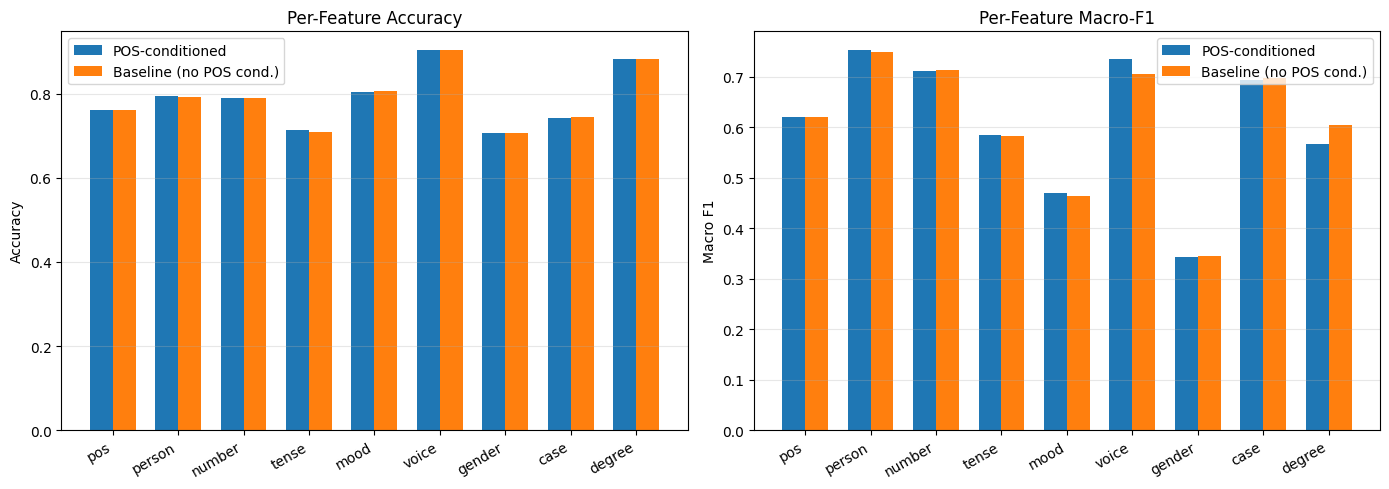

In [47]:
features = summary_df['feature'].tolist()
x = np.arange(len(features))
width = 0.35

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].bar(x - width/2, summary_df['acc_cond'], width, label='POS-conditioned')
axes[0].bar(x + width/2, summary_df['acc_ablation'], width, label='Baseline (no POS cond.)')
axes[0].set_xticks(x)
axes[0].set_xticklabels(features, rotation=30, ha='right')
axes[0].set_ylabel('Accuracy')
axes[0].set_title('Per-Feature Accuracy')
axes[0].legend()
axes[0].grid(axis='y', alpha=0.3)

axes[1].bar(x - width/2, summary_df['f1macro_cond'], width, label='POS-conditioned')
axes[1].bar(x + width/2, summary_df['f1macro_ablation'], width, label='Baseline (no POS cond.)')
axes[1].set_xticks(x)
axes[1].set_xticklabels(features, rotation=30, ha='right')
axes[1].set_ylabel('Macro F1')
axes[1].set_title('Per-Feature Macro-F1')
axes[1].legend()
axes[1].grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

/tmp/ipykernel_2492/1729116177.py:8: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(features, rotation=30, ha='right')


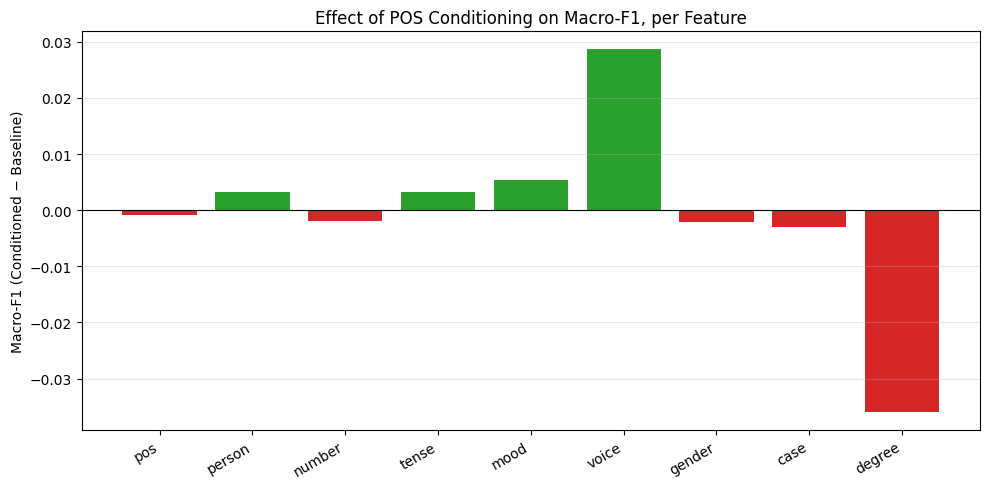

In [48]:
# Difference plot: positive = POS conditioning helps, negative = it hurts
fig, ax = plt.subplots(figsize=(10, 5))
colors = ['tab:green' if d >= 0 else 'tab:red' for d in summary_df['f1macro_diff']]
ax.bar(features, summary_df['f1macro_diff'], color=colors)
ax.axhline(0, color='black', linewidth=0.8)
ax.set_ylabel('Macro-F1 (Conditioned − Baseline)')
ax.set_title('Effect of POS Conditioning on Macro-F1, per Feature')
ax.set_xticklabels(features, rotation=30, ha='right')
ax.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()

In [49]:
def mcnemar_per_feature(preds_a, preds_b):
    """
    For each feature, build the 2x2 McNemar contingency table on paired
    predictions and return the test statistic + p-value.

        Cell b = A correct, B wrong
        Cell c = A wrong,   B correct
    """
    rows = []
    for feat in ALL_FEATS:
        if feat not in preds_a or not preds_a[feat]['y_true']:
            continue
        y_true = np.array(preds_a[feat]['y_true'])
        y_a    = np.array(preds_a[feat]['y_pred'])
        y_b    = np.array(preds_b[feat]['y_pred'])

        assert np.array_equal(y_true, np.array(preds_b[feat]['y_true'])), \
            f'Test sets differ for feature {feat} — pairing is invalid'

        a_correct = y_a == y_true
        b_correct = y_b == y_true

        # 2x2 contingency table
        n11 = np.sum( a_correct &  b_correct)
        n10 = np.sum( a_correct & ~b_correct)   # A right, B wrong
        n01 = np.sum(~a_correct &  b_correct)   # A wrong, B right
        n00 = np.sum(~a_correct & ~b_correct)

        table = [[n11, n10], [n01, n00]]
        # exact binomial when discordant pairs are few, chi-sq otherwise
        result = mcnemar(table, exact=(n10 + n01) < 25, correction=True)

        rows.append({
            'feature':      feat,
            'A_right_B_wrong': int(n10),
            'A_wrong_B_right': int(n01),
            'statistic':    result.statistic,
            'p_value':      result.pvalue,
            'significant_p<0.05': result.pvalue < 0.05,
        })
    return pd.DataFrame(rows)

# A = conditioned, B = ablation
mcnemar_df = mcnemar_per_feature(preds_cond, preds_ablation)
mcnemar_df.round(6)

,feature,A_right_B_wrong,A_wrong_B_right,statistic,p_value,significant_p<0.05
0,pos,154,152,0.003268,0.954413,False
1,person,63,50,1.274336,0.258955,False
2,number,95,107,0.599010,0.438956,False
3,tense,48,34,2.060976,0.151113,False
4,mood,31,41,1.125000,0.288844,False
5,voice,10,10,10.000000,1.000000,False
6,gender,61,64,0.032000,0.858028,False
7,case,64,73,0.467153,0.494300,False
8,degree,13,14,0.000000,1.000000,False


In [50]:
def per_label_diff(feat, reports_cond, reports_ablation, top_k=10):
    """Top-k labels where conditioning helps or hurts F1 the most."""
    if feat not in reports_cond or feat not in reports_ablation:
        return None
    rc, ra = reports_cond[feat], reports_ablation[feat]
    rows = []
    for label in rc:
        if label in ('accuracy', 'macro avg', 'weighted avg'):
            continue
        if label not in ra:
            continue
        rows.append({
            'label':           label,
            'support':         rc[label]['support'],
            'f1_cond':         rc[label]['f1-score'],
            'f1_ablation':     ra[label]['f1-score'],
            'f1_diff':         rc[label]['f1-score'] - ra[label]['f1-score'],
        })
    df = pd.DataFrame(rows).sort_values('f1_diff', ascending=False)
    return df

# Inspect every feature
for feat in ALL_FEATS:
    df = per_label_diff(feat, reports_cond, reports_ablation)
    if df is None or df.empty:
        continue
    print(f"\n{'='*60}")
    print(f"Feature: {feat.upper()}  (largest |f1_diff| first within sign)")
    print('='*60)
    print(df.round(4).to_string(index=False))


Feature: POS  (largest |f1_diff| first within sign)
label  support  f1_cond  f1_ablation  f1_diff
   I-     74.0   0.4330       0.4167   0.0163
   Px    294.0   0.4271       0.4141   0.0130
   Ps    231.0   0.5620       0.5524   0.0096
   Ne    629.0   0.4464       0.4382   0.0082
   Mo     35.0   0.3556       0.3478   0.0077
   G-    517.0   0.8836       0.8762   0.0074
   Nb   3159.0   0.6693       0.6668   0.0025
   Pp   1101.0   0.8905       0.8891   0.0014
   Df   1472.0   0.7843       0.7832   0.0011
   Pr    464.0   0.9509       0.9498   0.0010
   Pk     42.0   0.9880       0.9880   0.0000
   F-      0.0   0.0000       0.0000   0.0000
   Pc      1.0   0.0000       0.0000   0.0000
   C-   1335.0   0.9741       0.9757  -0.0016
   Pd    500.0   0.7316       0.7337  -0.0020
   V-   4073.0   0.7596       0.7620  -0.0025
   R-   1343.0   0.9492       0.9518  -0.0027
   Pi     90.0   0.8636       0.8671  -0.0034
   A-    671.0   0.3992       0.4030  -0.0038
   Dq     74.0   0.4167    